# Práctica 1. Representación y medida de un qubit

**Asignatura:** Computación Cuántica  
**Tema 1:** Conceptos fundamentales. Superposición cuántica  
**Duración estimada:** 45-55 minutos  
**Modalidad:** Individual o por parejas

En esta práctica representaremos estados de un qubit mediante vectores complejos, comprobaremos su normalización, aplicaremos la regla de Born y simularemos medidas en la base computacional. No utilizaremos Qiskit: trabajaremos directamente con el formalismo matemático mediante NumPy.

## Objetivos

Al finalizar la práctica serás capaz de:

- Representar estados de un qubit como vectores complejos.
- Validar y normalizar vectores de estado.
- Calcular probabilidades mediante la regla de Born.
- Simular una o varias medidas en la base computacional.
- Comparar probabilidades teóricas y frecuencias experimentales.
- Analizar el efecto del número de *shots*.
- Identificar estados diferentes que producen el mismo histograma en una base concreta.

> Completa todas las celdas marcadas con `TODO` y responde en Markdown a las preguntas planteadas.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

np.set_printoptions(precision=5, suppress=True)

## Parte A. Representación de estados

### Ejercicio 1. Base computacional

Representa los estados

$$|0\rangle=\begin{pmatrix}1\\0\end{pmatrix},\qquad |1\rangle=\begin{pmatrix}0\\1\end{pmatrix}.$$

Muestra los vectores, su forma, el tipo de sus componentes y su norma.

In [4]:
# TODO: crea los estados con dtype=complex
ket_0 = np.array([1,0], dtype=complex) # vamos a trabajar siempre con complejos.
ket_1 = np.array([0,1], dtype=complex)

# TODO: muestra vector, shape, dtype y norma de cada estado

print(f"ket_0: {ket_0}, Forma: {ket_0.shape}, Dtype: {ket_0.dtype}, Norma: {np.linalg.norm(ket_0)}, {np.isclose(np.linalg.norm(ket_0), 1.0, atol=1e-10)}")
print(f"ket_1: {ket_1}, Forma: {ket_1.shape}, Dtype: {ket_1.dtype}, Norma: {np.linalg.norm(ket_1)}, {np.isclose(np.linalg.norm(ket_1), 1.0, atol=1e-10)}")



ket_0: [1.+0.j 0.+0.j], Forma: (2,), Dtype: complex128, Norma: 1.0, True
ket_1: [0.+0.j 1.+0.j], Forma: (2,), Dtype: complex128, Norma: 1.0, True


**Responde:**

1. ¿Por qué los arrays deben admitir números complejos?
2. ¿Qué dimensión tiene el espacio de estados de un qubit?
3. ¿Qué valor debe tener la norma de un estado válido?

**Respuesta:** 
1. Porque las amplitudes cuánticas pueden ser números complejos.
2. Tiene dimensión 2
3. Para saber que estan normalizados los valores de los estados válidos, debe tener la norma el resultado 1.

### Ejercicio 2. Superposiciones

Representa los siguientes estados y, para cada uno, muestra el vector, sus amplitudes, su norma y si está normalizado:

$$|\psi_1\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}$$

$$|\psi_2\rangle=\frac{\sqrt{3}}{2}|0\rangle+\frac{1}{2}|1\rangle$$

$$|\psi_3\rangle=\frac{1}{\sqrt{2}}|0\rangle+\frac{i}{\sqrt{2}}|1\rangle$$

$$|\psi_4\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$

In [5]:
# TODO: representa los cuatro estados
psi_1 = np.array([1/np.sqrt(2), 1/np.sqrt(2)], dtype=complex)
psi_2 = np.array([np.sqrt(3)/2, 1/2], dtype = complex)
psi_3 = np.array([1/np.sqrt(2), 1j/np.sqrt(2)], dtype= complex)
psi_4 = np.array([(1+1j) / 2, (1-1j) / 2], dtype=complex)

estados = {
    "psi_1": psi_1,
    "psi_2": psi_2,
    "psi_3": psi_3,
    "psi_4": psi_4,
}

# TODO: recorre el diccionario y muestra los datos solicitados
# Usa np.isclose para comprobar la normalización

for nombre, estado in estados.items():
    print(f"Nombre: {nombre}, Alfa:{estado[0]:.3f} Beta:{estado[1]:.3f}, Forma: {estado.shape}, Norma: {np.linalg.norm(estado):.3f}, Normalizado:{'Si' if  np.isclose(np.linalg.norm(estado), 1.0, atol=1e-10) else 'No'}")


Nombre: psi_1, Alfa:0.707+0.000j Beta:0.707+0.000j, Forma: (2,), Norma: 1.000, Normalizado:Si
Nombre: psi_2, Alfa:0.866+0.000j Beta:0.500+0.000j, Forma: (2,), Norma: 1.000, Normalizado:Si
Nombre: psi_3, Alfa:0.707+0.000j Beta:0.000+0.707j, Forma: (2,), Norma: 1.000, Normalizado:Si
Nombre: psi_4, Alfa:0.500+0.500j Beta:0.500-0.500j, Forma: (2,), Norma: 1.000, Normalizado:Si


**Responde:**

1. ¿Por qué no conviene comprobar números en coma flotante con `valor == 1.0`?
2. ¿Puede un estado válido contener amplitudes imaginarias?
3. ¿Implica una amplitud imaginaria que la probabilidad sea imaginaria?

**Respuesta:**

1. Porque los números en coma flotante tienen pequeños errores de precisión; es mejor usar np.isclose().

2. Sí, las amplitudes pueden ser imaginarias o complejas.

3. No. La probabilidad es el módulo al cuadrado y siempre es real y no negativa.

## Parte B. Validación y normalización

### Ejercicio 3. Validación de estados

Completa una función que verifique que la entrada tiene dos amplitudes, contiene valores finitos y posee norma uno. El vector nulo y los vectores con otra dimensión no son estados válidos de un qubit.

In [6]:
def es_estado_valido(estado, tolerancia=1e-10):
    """Devuelve True si estado representa un estado válido de un qubit."""
    try:
        vector = np.asarray(estado, dtype=complex)
    except (ValueError, TypeError):
        return False, "El estado no se puede convertir a una array de tipo complejo."
    if not np.all(np.isfinite(vector)):
        return False, "El estado contiene valores infinitos o NaN."
    if vector.shape != (2,):
        return False, f"El estado tiene forma{vector.shape}, pero debería ser (2,)."
    norma= np.linalg.norm(estado)
    if not np.isclose(norma, 1.0, atol= tolerancia):
        return False, "0"
    return True, "El estado es válido."


casos = {
    "ket_0": [1, 0],
    "ket_1": [0, 1],
    "equilibrado": [1 / np.sqrt(2), 1 / np.sqrt(2)],
    "no_normalizado": [1, 1],
    "vector_nulo": [0, 0],
    "dimension_incorrecta": [1, 0, 0],
    "con_nan": [np.nan, 0],
}

# TODO: muestra si cada caso es válido y justifica brevemente el resultado
for nombre, caso in casos.items():
    valido, mensaje=es_estado_valido(caso)
    print(f"Nombre: {nombre:<20}, Estado:{str(caso):<10}, Valido:{valido}, Justificacion: {mensaje}")

Nombre: ket_0               , Estado:[1, 0]    , Valido:True, Justificacion: El estado es válido.
Nombre: ket_1               , Estado:[0, 1]    , Valido:True, Justificacion: El estado es válido.
Nombre: equilibrado         , Estado:[np.float64(0.7071067811865475), np.float64(0.7071067811865475)], Valido:True, Justificacion: El estado es válido.
Nombre: no_normalizado      , Estado:[1, 1]    , Valido:False, Justificacion: 0
Nombre: vector_nulo         , Estado:[0, 0]    , Valido:False, Justificacion: 0
Nombre: dimension_incorrecta, Estado:[1, 0, 0] , Valido:False, Justificacion: El estado tiene forma(3,), pero debería ser (2,).
Nombre: con_nan             , Estado:[nan, 0]  , Valido:False, Justificacion: El estado contiene valores infinitos o NaN.


### Ejercicio 4. Normalización

Completa la función. Debe convertir la entrada a un array complejo, comprobar su dimensión y finitud, rechazar el vector nulo y devolver un vector de norma uno.

In [7]:
def normalizar_estado(estado):
    """Normaliza un vector de dos amplitudes complejas."""
    # TODO
    mensaje = None
    if es_estado_valido(estado)[0] == False:
        if es_estado_valido(estado)[1] == "0":
            norma = np.linalg.norm(estado)
            if np.isclose(norma, 0.0, atol= 1e-10):
                raise ValueError("No se puede normalizar un vector nulo")

            estado= estado/norma
            mensaje="El estado se ha normalizado"
            
        else:
            mensaje= "No es un estado valido"
    else:
        mensaje= "El estado está normalizado"
    return estado, mensaje


vectores = [
    np.array([1, 1], dtype=complex),
    np.array([3, 4], dtype=complex),
    np.array([1 + 1j, 2 - 1j], dtype=complex),
]

# TODO: muestra vector y norma antes y después de normalizar

for i, vector in enumerate(vectores):
    estado, mensaje= normalizar_estado(vector)
    print(f"Vector:{vector}, Norma: {np.linalg.norm(vector)}, Normalizacion: {estado}, Norma_normalizado: {es_estado_valido(estado)}")


Vector:[1.+0.j 1.+0.j], Norma: 1.4142135623730951, Normalizacion: [0.70711+0.j 0.70711+0.j], Norma_normalizado: (True, 'El estado es válido.')
Vector:[3.+0.j 4.+0.j], Norma: 5.0, Normalizacion: [0.6+0.j 0.8+0.j], Norma_normalizado: (True, 'El estado es válido.')
Vector:[1.+1.j 2.-1.j], Norma: 2.6457513110645907, Normalizacion: [0.37796+0.37796j 0.75593-0.37796j], Norma_normalizado: (True, 'El estado es válido.')


**Responde:**

1. ¿Cambia la dirección del vector al normalizarlo?
2. ¿Qué ocurre con la relación entre sus componentes?
3. ¿Por qué no puede normalizarse el vector nulo?

**Respuesta:** 
1. No cambia la direccion del vector al normalizarlo, solo cambia la longitud del vector
2. La proporción entre sus componentes se mantiene.
3. El vector nulo no puede realizarse debido a que el resultado de su normalizacion seria una division entre 0, produciendo un resultado infinito.

## Parte C. Regla de Born

### Ejercicio 5. Probabilidades de medida

Para $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$, la regla de Born establece $P(0)=|\alpha|^2$ y $P(1)=|\beta|^2$. Completa la función sin utilizar `estado ** 2`.

In [8]:
def calcular_probabilidades(estado):
    """Devuelve {0: P(0), 1: P(1)} para un estado válido."""
    # TODO
    normalizar_estado(estado)
    proba_0= np.abs(estado[0])**2
    proba_1= np.abs(estado[1])**2
    return proba_0 , proba_1


# TODO: aplica la función a ket_0, ket_1 y psi_1...psi_4s
# Comprueba en todos los casos que P(0) + P(1) = 1
ket_0, ket_1=casos["ket_0"], casos["ket_1"]
array_estados = [ket_0,ket_1]

for estado in estados.values():
    array_estados.append(estado)

for i,estado in enumerate(array_estados):
    print(calcular_probabilidades(estado))

(np.int64(1), np.int64(0))
(np.int64(0), np.int64(1))
(np.float64(0.4999999999999999), np.float64(0.4999999999999999))
(np.float64(0.7499999999999999), np.float64(0.25))
(np.float64(0.4999999999999999), np.float64(0.4999999999999999))
(np.float64(0.5000000000000001), np.float64(0.5000000000000001))


### Ejercicio 6. Cálculo manual con amplitudes complejas

Considera

$$|\psi\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$

Calcula manualmente $\alpha$, $\beta$, $|\alpha|^2$, $|\beta|^2$, $P(0)$ y $P(1)$. Después compruébalo con la función anterior.

**Desarrollo y respuesta:** 

$\alpha$ = 1+i / 2

$\beta$ = 1-i / 2 

$|\beta|^2$ = 1+i / 2 * 1-i / 2 = 1/2

$|\alpha|^2$ = 1+i / 2 * 1-i / 2 = 1/2

$P(0)$ = 50%
$P(1)$ = 50%



In [9]:
# TODO: comprobación computacional del ejercicio 6
estado = np.array([(1+1j)/2, (1-1j)/2], dtype=complex)

calcular_probabilidades(estado)

(np.float64(0.5000000000000001), np.float64(0.5000000000000001))

## Parte D. Simulación de la medida

### Ejercicio 7. Una medida

Completa la función para simular una medida en la base computacional. Debe devolver el entero 0 o 1 de acuerdo con las probabilidades del estado.

In [10]:


def medir(estado, rng=None):
    """Simula una medida del qubit en la base computacional."""
    if rng is None:
        rng = np.random.default_rng(SEMILLA)
    P0, P1=calcular_probabilidades(estado)
    return rng.choice([0,1], p = [P0, P1])



# TODO: mide ket_0, ket_1, psi_1 y psi_2
for i in range(0,4):
    print(medir(array_estados[i]))
    

0
1
1
1


**Responde:**

1. ¿Qué debe producir siempre $|0\rangle$? ¿Y $|1\rangle$?
2. ¿Permite una medida aislada conocer $\alpha$ y $\beta$?
3. Si obtenemos 0, ¿podemos afirmar que el estado inicial era $|0\rangle$?

**Respuesta:** 
1. |0> siempre produce 0 y |1> siempre produce 1.
2. Una medida aislada no nos permita conocer las amplitudes
3. No. Otros estados también pueden producir 0 al medir.

### Ejercicio 8. Medidas repetidas

Cada *shot* representa una nueva preparación del mismo estado seguida de una medida. La función debe rechazar valores de `shots` que no sean enteros positivos.

In [11]:

i = -1
resultados_experimento=[]
def medir_repetidamente(estado, shots=1000, semilla=None):
    """Devuelve {0: número de ceros, 1: número de unos}."""
    if semilla is None:
        rng= np.random.default_rng(semilla)
    
        
    rng= np.random.default_rng(semilla)
    prob=calcular_probabilidades(estado)
    muestras= rng.choice([0,1], size=shots, p=[prob[0], prob[1]])
    conteos = np.bincount(muestras, minlength=2)
    return {0: conteos[0], 1: conteos[1]}

shots_estudiados = [10, 100, 1_000, 10_000, 100_000]
p0, p1= calcular_probabilidades(psi_2)
for shot in shots_estudiados:
    i=1+i
    conteos = medir_repetidamente(psi_2, shot)
    f0, f1 = conteos[0]/shot, conteos[1]/shot
    e0,e1 = abs(f0-p0), abs(f1-p1)

    resultados_experimento.append({"shots": shot, "n_0": conteos[0], "n_1": conteos[1], "f_0": f0, "f_1": f1, "e_0": e0, "e_1":e1})
    print(resultados_experimento[i])


# TODO: experimenta con psi_2 y calcula conteos, frecuencias y errores absolutos
# Guarda una fila por número de shots en resultados_experimento

{'shots': 10, 'n_0': np.int64(8), 'n_1': np.int64(2), 'f_0': np.float64(0.8), 'f_1': np.float64(0.2), 'e_0': np.float64(0.050000000000000155), 'e_1': np.float64(0.04999999999999999)}
{'shots': 100, 'n_0': np.int64(77), 'n_1': np.int64(23), 'f_0': np.float64(0.77), 'f_1': np.float64(0.23), 'e_0': np.float64(0.02000000000000013), 'e_1': np.float64(0.01999999999999999)}
{'shots': 1000, 'n_0': np.int64(752), 'n_1': np.int64(248), 'f_0': np.float64(0.752), 'f_1': np.float64(0.248), 'e_0': np.float64(0.002000000000000113), 'e_1': np.float64(0.0020000000000000018)}
{'shots': 10000, 'n_0': np.int64(7542), 'n_1': np.int64(2458), 'f_0': np.float64(0.7542), 'f_1': np.float64(0.2458), 'e_0': np.float64(0.0042000000000000925), 'e_1': np.float64(0.004200000000000009)}
{'shots': 100000, 'n_0': np.int64(74984), 'n_1': np.int64(25016), 'f_0': np.float64(0.74984), 'f_1': np.float64(0.25016), 'e_0': np.float64(0.00015999999999993797), 'e_1': np.float64(0.00015999999999999348)}


Completa la tabla con tus resultados:

| Shots | $N(0)$ | $N(1)$ | $f(0)$ | $f(1)$ | $E_0$ | $E_1$ |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 9| 1| 0.9| 0.1| 0.150| 0.150|
| 100 | 76| 24| 0.760| 0.240| 0.010| 0.010|
| 1.000 | 774| 226| 0,774| 0,226| 0,024| 0,024|
| 10.000 | 7.522| 2.478| 0,7522| 0,2478| 0,0022| 0,0022|
| 100.000 | 74.843| 25.157| 0,74843| 0,25157| 0,00157| 0,00157|

**Responde:** ¿Coinciden exactamente frecuencias y probabilidades? ¿Qué ocurre al aumentar los shots? ¿Debe disminuir el error de forma estrictamente monótona? ¿Se mide repetidamente el mismo qubit después de su colapso?

**Respuesta:** Las frecuencias no tienen que coincidir exactamente con las probabilidades. Al aumentar los shots, normalmente se aproximan más a ellas. El error no disminuye de forma estrictamente monótona por el azar. Cada shot usa una nueva preparación del mismo estado, no el mismo qubit ya colapsado.

## Parte E. Visualización

### Ejercicio 9. Convergencia de la frecuencia

Representa la frecuencia experimental de obtener 0 frente al número de shots. Añade una línea horizontal para la probabilidad teórica $P(0)=0{,}75$ y usa escala logarítmica en el eje horizontal. Incluye título, etiquetas, leyenda y cuadrícula.

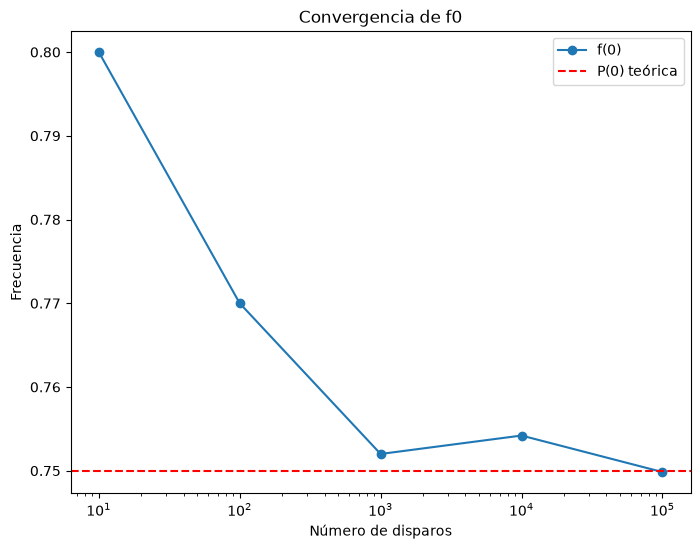

In [12]:
# TODO: representa la convergencia de f(0)
# Sugerencia: plt.xscale("log")
plt.figure(figsize=(8,6))
shots=[resultado["shots"] for resultado in resultados_experimento]
f0 = [resultado["f_0"] for resultado in resultados_experimento]

plt.plot(shots, f0, 'o-', label = "f(0)")
plt.axhline(y= p0, color="r", linestyle = "--",label = "P(0) teórica")
plt.xlabel("Número de disparos")
plt.ylabel("Frecuencia")
plt.title("Convergencia de f0")
plt.xscale("log")
plt.legend()
plt.show()


**Interpretación de la gráfica (4-6 líneas):** Al aumentar los shots, la frecuencia de obtener 0 tiende a acercarse a (P(0)=0,75). Con pocos shots hay más fluctuaciones. Con muchos shots la estimación suele ser más estable. La convergencia no tiene que ser perfectamente continua.

### Ejercicio 10. Histograma de resultados

Para 1.000 shots, representa un diagrama de barras con los conteos de 0 y 1. Añade el valor numérico sobre cada barra.

C:\Users\Francisco Jose\AppData\Local\Temp\ipykernel_27452\489509933.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


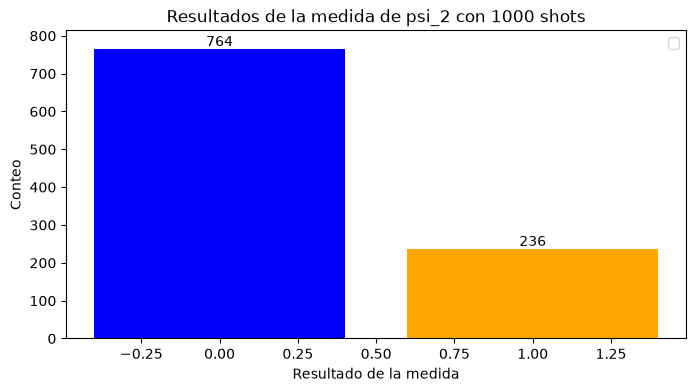

In [13]:
# TODO: representa el histograma de conteos
conteos_1000 = medir_repetidamente(psi_2, shots= 1000)

fig, ax = plt.subplots(figsize =(8,4))
barras= ax.bar(conteos_1000.keys(), conteos_1000.values(), color=["blue", "orange"])

ax.bar_label(barras)
ax.set_xlabel("Resultado de la medida")
ax.set_ylabel("Conteo")
ax.set_title("Resultados de la medida de psi_2 con 1000 shots")
ax.set_ylim(0, max(conteos_1000.values()) + 50)
ax.legend()
plt.show()

**Responde:** ¿Qué información muestra el histograma? ¿Muestra directamente las amplitudes? ¿Permite determinar la fase relativa?

**Respuesta:** El histograma muestra cuántas veces aparece cada resultado, 0 o 1. No muestra directamente las amplitudes. Tampoco permite conocer la fase relativa.

## Parte F. Estados con las mismas probabilidades

### Ejercicio 11. El papel de la fase

Compara los estados

$$|\psi_A\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}},\qquad |\psi_B\rangle=\frac{|0\rangle-|1\rangle}{\sqrt{2}},\qquad |\psi_C\rangle=\frac{|0\rangle+i|1\rangle}{\sqrt{2}}.$$

Represéntalos, valida su normalización, calcula sus probabilidades y simula 10.000 medidas de cada uno.

C:\Users\Francisco Jose\AppData\Local\Temp\ipykernel_27452\4144538664.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


El estado psi_A: La normalizacion es [0.70711+0.j 0.70711+0.j], su probabilidad es 0.4999999999999999


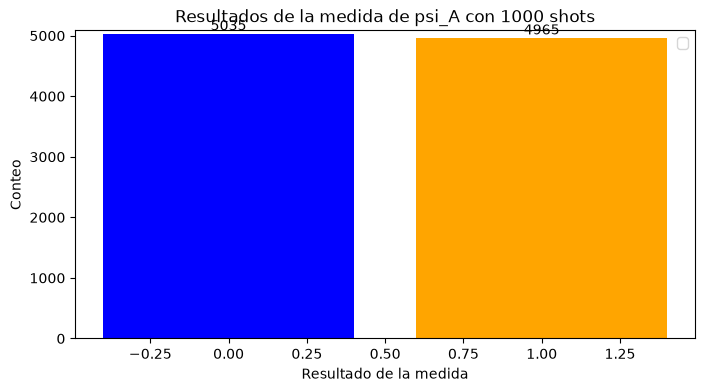

El estado psi_B: La normalizacion es [ 0.70711+0.j -0.70711+0.j], su probabilidad es 0.4999999999999999


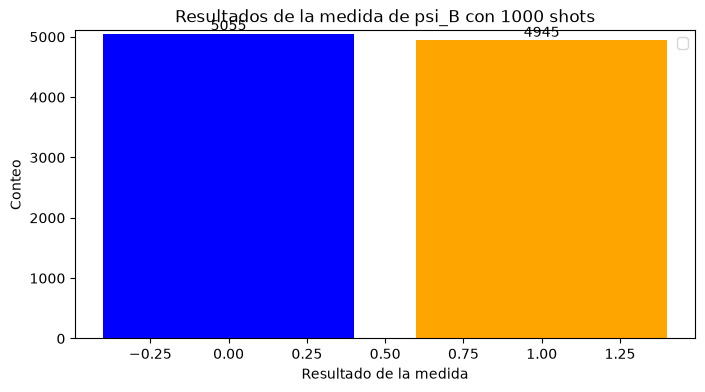

El estado psi_C: La normalizacion es [0.70711+0.j      0.     +0.70711j], su probabilidad es 0.4999999999999999


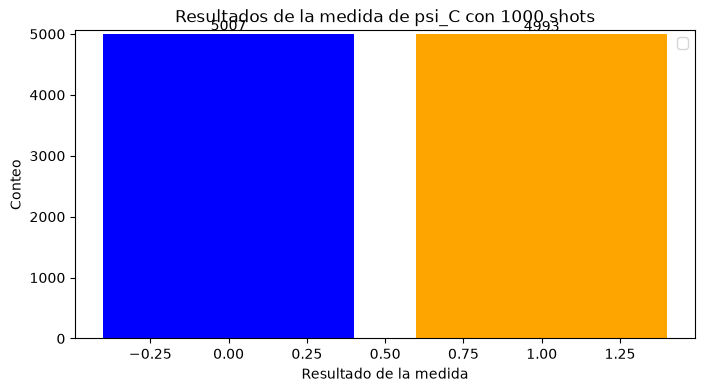

In [14]:
# TODO: representa y compara psi_A, psi_B y psi_C
psi_A = np.array([1/np.sqrt(2), 1/np.sqrt(2)],dtype=complex)
psi_B = np.array([1/np.sqrt(2), -1/np.sqrt(2)],dtype=complex)
psi_C = np.array([1/np.sqrt(2), 1j/np.sqrt(2)],dtype=complex)

estados_psi = {
    "psi_A": psi_A,
    "psi_B": psi_B,
    "psi_C": psi_C
}

for key, value in estados_psi.items():
    print(f"El estado {key}: La normalizacion es {normalizar_estado(value)[0]}, su probabilidad es {calcular_probabilidades(value)[1]}")
    conteos_10000 = medir_repetidamente(value, shots= 10000)

    fig, ax = plt.subplots(figsize =(8,4))
    barras= ax.bar(conteos_10000.keys(), conteos_10000.values(), color=["blue", "orange"])

    ax.bar_label(barras)
    ax.set_xlabel("Resultado de la medida")
    ax.set_ylabel("Conteo")
    ax.set_title(f"Resultados de la medida de {key} con 1000 shots")
    ax.set_ylim(0, max(conteos_10000.values()) + 50)
    ax.legend()
    plt.show()


**Responde:**

1. ¿Son iguales los tres vectores?
2. ¿Producen las mismas probabilidades en la base computacional?
3. ¿Podemos concluir que representan el mismo estado?
4. ¿Permite esta medida detectar sus diferencias?
5. ¿Qué información no aparece en los histogramas?
6. ¿Qué fenómeno permitirá aprovechar posteriormente estas diferencias?

**Respuesta:** 

-    No, los tres vectores son diferentes.
-    Sí, todos producen probabilidades (1/2) y (1/2).
-    No, tienen fases relativas diferentes.
-    No, medir solo en la base computacional no las distingue.
-    No aparece la información de fase.
-    La interferencia cuántica permite aprovechar esas diferencias.

### Ejercicio 12. Fase global y fase relativa

Compara

$$|\phi_A\rangle=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},\quad |\phi_B\rangle=-\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},\quad |\phi_C\rangle=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\-1\end{pmatrix}.$$

¿Qué estados se diferencian solo por una fase global? ¿Dónde hay una diferencia de fase relativa? ¿Cuáles son físicamente equivalentes?

**Respuesta razonada:** phi_A y phi_B solo se diferencian por una fase global -1, por lo que son físicamente equivalentes. phi_C tiene una fase relativa diferente entre sus componentes y no es equivalente a los otros dos.

## Parte G. Construcción segura de estados

### Ejercicio 13. Función de construcción

Completa una función que acepte amplitudes reales o complejas, rechace valores no finitos y el vector nulo, y devuelva el estado normalizado.

In [15]:
def crear_estado(alpha, beta):
    """Construye y normaliza el estado de un qubit."""
    try:
        estado = np.array([alpha, beta], dtype=complex)
    except(ValueError, TypeError):
        print("No se puede construir un estado con las siguientes amplitudes.")

    if not np.all(np.isfinite(estado)):
        raise ValueError("ERROR: El estado es finito o un valor nulo") 

    return normalizar_estado(estado)

# TODO: prueba la función con alpha=1+2j y beta=3-1j
print(crear_estado(1+2j, 3-1j))

(array([0.2582+0.5164j, 0.7746-0.2582j]), 'El estado se ha normalizado')


**Responde:** ¿Es siempre conveniente normalizar automáticamente una entrada? ¿En qué contexto sería preferible lanzar una excepción? ¿Puede la normalización ocultar un error matemático?

**Respuesta:** No siempre conviene normalizar automáticamente. Si se espera recibir un estado ya normalizado, es mejor lanzar una excepción ante una entrada incorrecta. Sí, normalizar automáticamente puede ocultar un error matemático previo.

## Reto avanzado. Incertidumbre estadística

Para una variable binaria con probabilidad $p$, la desviación típica de la frecuencia estimada con $N$ shots es

$$\sigma_f=\sqrt{\frac{p(1-p)}{N}}.$$

Con $p=0{,}75$, calcula $\sigma_f$ para todos los números de shots anteriores y añade a la gráfica las curvas $p-\sigma_f$ y $p+\sigma_f$.

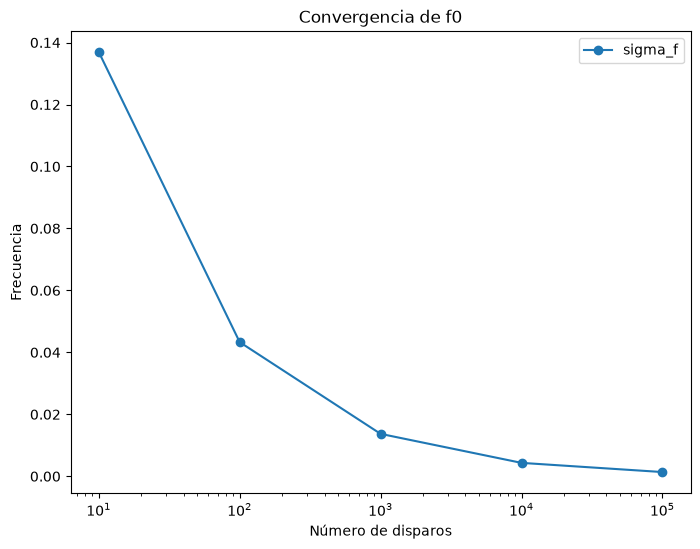

In [16]:
# TODO: calcula sigma_f y representa las bandas de incertidumbre
p= 0.75
q= 1-p 
shots_estudiados # Es la cantidad de shots
sigma_array=[]

for n in shots_estudiados:
    sigma_array.append({"shot": n, "sigma_f":np.sqrt((p*q) / n)})

plt.figure(figsize=(8,6))


shot = [sigma["shot"] for sigma in sigma_array]
sigma_f = [sigma["sigma_f"] for sigma in sigma_array]

plt.plot(shot,sigma_f, 'o-', label = "sigma_f")
plt.xlabel("Número de disparos")
plt.ylabel("Frecuencia")
plt.title("Convergencia de f0")
plt.xscale("log")
plt.legend()
plt.show()


**Responde:** ¿Cómo varía la incertidumbre con $N$? ¿Cuántos shots hacen falta aproximadamente para reducirla a la mitad? ¿Por qué aumentar shots presenta rendimiento decreciente?

**Respuesta:** La incertidumbre disminuye como (1/\sqrt{N}). Para reducirla a la mitad hacen falta aproximadamente cuatro veces más shots. Por eso existe rendimiento decreciente: aumentar mucho los shots produce mejoras cada vez menores.

## Pruebas mínimas

Ejecuta estas pruebas después de completar las funciones y añade las necesarias para comprobar entradas no válidas.

In [17]:
# Descomenta cuando hayas implementado las funciones.

assert es_estado_valido([1, 0])
assert es_estado_valido([0, 1])
assert not es_estado_valido([1, 1])[0]
assert not es_estado_valido([0, 0])[0]
assert not es_estado_valido([1, 0, 0])[0]
assert np.isclose(np.linalg.norm(normalizar_estado([1, 1])[0]), 1.0)
assert np.isclose(sum(calcular_probabilidades(psi_2)), 1.0)
assert medir(psi_1, np.random.default_rng(42)) in (0, 1)
assert sum(medir_repetidamente(psi_2, 1000, 42).values()) == 1000



assert not es_estado_valido([np.nan, 0])[0]
assert not es_estado_valido([np.inf, 0])[0]
assert not es_estado_valido(["a", 0])[0]

complejo = [1 / np.sqrt(2), 1j / np.sqrt(2)]
assert es_estado_valido(complejo)[0]

try:
    normalizar_estado(np.array([0, 0], dtype=complex))
    assert False
except ValueError:
    pass

try:
    crear_estado(np.nan, 1)
    assert False
except ValueError:
    pass

print("Todas las pruebas mínimas se han superado correctamente.")
# TODO: añade pruebas de excepciones y otros casos límite

Todas las pruebas mínimas se han superado correctamente.


## Conclusiones

Redacta un máximo de 200 palabras respondiendo:

1. ¿Qué diferencia existe entre amplitud y probabilidad?
2. ¿Qué relación existe entre shots, frecuencias y probabilidades?
3. ¿Por qué una sola medida no permite reconstruir el estado?
4. ¿Por qué dos estados diferentes pueden producir el mismo histograma?
5. ¿Qué diferencia conceptual existe entre una superposición y una mezcla clásica?

**Conclusión:** 

La amplitud puede ser compleja, mientras que la probabilidad es su módulo al cuadrado. Los shots son repeticiones del experimento y sus frecuencias se aproximan a las probabilidades al aumentar su número. Una sola medida solo proporciona un resultado, por lo que no permite reconstruir el estado. Estados diferentes pueden producir el mismo histograma si tienen iguales probabilidades en la base utilizada pero distintas fases. Una superposición cuántica mantiene amplitudes y fases capaces de interferir, mientras que una mezcla clásica representa únicamente incertidumbre probabilística entre estados

## Lista de comprobación antes de entregar

- [ ] Todas las celdas se ejecutan en orden sin errores.
- [ ] No quedan bloques `TODO` sin completar.
- [ ] Las probabilidades suman uno.
- [ ] Las gráficas tienen títulos, etiquetas y leyendas.
- [ ] Las respuestas justifican los resultados.
- [ ] Las pruebas mínimas se ejecutan correctamente.
- [ ] El notebook conserva las salidas antes de la entrega.